# Input

In [1]:
# Relevant files you'll want to upload
# 1. combined-oc-pic-tasks.csv
# 2. combined-oc-pic-code-reviews.csv

from google.colab import files
uploaded = files.upload()

Saving combined-oc-pic-tasks.csv to combined-oc-pic-tasks.csv
Saving task-repos.csv to task-repos.csv
Saving combined-oc-pic-code-reviews.csv to combined-oc-pic-code-reviews.csv


# Algorithms

In [2]:
import pandas as pd
from scipy import stats


# Data Loading
try:
    tasks_df_pre = pd.read_csv('combined-oc-pic-tasks.csv')
except FileNotFoundError:
    print("Error: The file 'combined-oc-pic-tasks.csv' was not found.")
    print("Please ensure the file is in the same directory as this script.")
    exit()

try:
    crs_df_pre = pd.read_csv('combined-oc-pic-code-reviews.csv')
except FileNotFoundError:
    print("Error: The file 'combined-oc-pic-code-reviews.csv' was not found.")
    print("Please ensure the file is in the same directory as this script.")
    exit()


# Data augmentation
tasks_df_pre['time_open_days'] = tasks_df_pre['timeOpen'] / (1000 * 60 * 60 * 24)
crs_df_pre['time_open_days']   = crs_df_pre['timeOpen']   / (1000 * 60 * 60 * 24)

# Data cleaning
tasks_df = tasks_df_pre[tasks_df_pre['priority'] != 'other'] # remove private tasks since the data they have in any row is default data besides the ID
crs_df = crs_df_pre
#tasks_df = df_pre.dropna(subset=['time_open_days'])

print("Num tasks before cleaning", len(tasks_df_pre))
print("Num tasks remaining after cleaning", len(tasks_df))


# Convenience Vars
pic_tasks = tasks_df[tasks_df['source'] == 'PIC']
oc_tasks = tasks_df[tasks_df['source'] == 'OC']
closed_tasks = tasks_df[tasks_df['isClosed'] == True]
closed_pic_tasks = closed_tasks[closed_tasks['source'] == 'PIC']
closed_oc_tasks = closed_tasks[closed_tasks['source'] == 'OC']

pic_crs = crs_df[crs_df['source'] == 'PIC']
oc_crs = crs_df[crs_df['source'] == 'OC']
merged_or_abandoned_crs = crs_df[crs_df['status'] != 'NEW'] # MERGED or ABANDONED
merged_or_abandoned_pic_crs = merged_or_abandoned_crs[merged_or_abandoned_crs['source'] == 'PIC']
merged_or_abandoned_oc_crs = merged_or_abandoned_crs[merged_or_abandoned_crs['source'] == 'OC']


# Automatically select numerical columns for the scatter plot matrix from the tasks_df DataFrame
numerical_cols_tasks = tasks_df.select_dtypes(include=['number']).columns.tolist()
# Remove 'timeOpen' if it was included, as 'time_open_days' is preferred for analysis
numerical_cols_tasks = [col for col in numerical_cols_tasks if col not in ['timeOpen']]
# Ensure 'time_open_days' is included if it exists in the DataFrame
if 'time_open_days' not in numerical_cols_tasks and 'time_open_days' in tasks_df.columns:
    numerical_cols_tasks.append('time_open_days')

# Automatically select numerical columns for the scatter plot matrix from the crs_df DataFrame
numerical_cols_crs = crs_df.select_dtypes(include=['number']).columns.tolist()
# Remove 'timeOpen' if it was included, as 'time_open_days' is preferred for analysis
numerical_cols_crs = [col for col in numerical_cols_crs if col not in ['timeOpen']]
# Ensure 'time_open_days' is included if it exists in the DataFrame
if 'time_open_days' not in numerical_cols_crs and 'time_open_days' in crs_df.columns:
    numerical_cols_crs.append('time_open_days')


# Algorithms
# --- Helpers to perform the Mann-Whitney U Test ---

import pandas as pd
from scipy.stats import mannwhitneyu
import numpy as np

def calculate_effect_size_r_stable(u_stat, n1, n2):
    """
    Calculates the effect size (r) for the Mann-Whitney U test using the stable
    normal approximation derived from the U-statistic.

    Args:
        u_stat (float): The calculated U statistic (from mannwhitneyu).
        n1 (int): Sample size of the first group (PIC).
        n2 (int): Sample size of the second group (OC).

    Returns:
        float: The calculated effect size (r).
    """
    N_total = n1 + n2

    # 1. Calculate the mean (mu) and standard deviation (sigma) of U under H0
    mu_U = (n1 * n2) / 2
    sigma_U = np.sqrt( (n1 * n2 * (n1 + n2 + 1)) / 12 ) # Note: This is without tie correction

    # 2. Calculate the Z-statistic (using the continuity correction of 0.5 is optional, but robust)
    # The sign is handled naturally by U_stat - mu_U
    # Adding a small epsilon to sigma_U to avoid division by zero in case of very small samples
    Z_stat = (u_stat - mu_U) / (sigma_U + 1e-9)

    # 3. Calculate the effect size (r)
    if N_total == 0:
        return 0

    effect_size_r = Z_stat / np.sqrt(N_total)

    return effect_size_r


def perform_mannwhitneyu_test(test_description, data_pic, data_oc, column_name, alternative='two-sided', alpha=0.05):
    """
    Performs a Mann-Whitney U test, calculates effect size (r), and prints the results.

    Args:
        test_description (str): A description of the test being performed.
        data_pic (pd.DataFrame): DataFrame for PIC data.
        data_oc (pd.DataFrame): DataFrame for OC data.
        column_name (str): The name of the column to test.
        alternative (str): Defines the alternative hypothesis.
                           Options are 'two-sided', 'less', 'greater'.
        alpha (float): The significance level.
    """
    pic_data = data_pic[column_name].dropna()
    oc_data = data_oc[column_name].dropna()

    n1 = len(pic_data)
    n2 = len(oc_data)

    if n1 == 0 or n2 == 0:
        print(f"\nSkipping test for '{column_name}': Not enough data in one or both groups.")
        return

    u_stat, p_value = mannwhitneyu(pic_data, oc_data, alternative=alternative)

    # Calculate effect size (r) using the stable function
    # Note: calculate_effect_size_r_stable uses the U statistic from the test result.
    # The sign of the Z_stat in calculate_effect_size_r_stable correctly reflects the direction
    # based on how the U statistic deviates from its expected mean under the null.
    effect_size_r = calculate_effect_size_r_stable(u_stat, n1, n2)

    conclusion = ""
    if p_value < alpha:
        conclusion = f"\nCONCLUSION: Reject the Null Hypothesis (p < {alpha}, U = {u_stat}). "
        if alternative == 'less':
            conclusion = conclusion + f"The median {column_name} for PIC is **significantly less** than for OC."
        elif alternative == 'greater':
            conclusion = conclusion + f"The median {column_name} for PIC is **significantly greater** than for OC."
        else:
             conclusion = conclusion + f"The median {column_name} is **significantly different** between PIC and OC."
    else:
         conclusion = f"\nCONCLUSION: Fail to Reject the Null Hypothesis (p > {alpha}). We did not find significant evidence of a difference in median {column_name}."


    print("\n" + "-" * 50)
    print(f"Mann-Whitney U Test: {test_description} {conclusion}")
    header = ["--",  " N ", "Mean", "Min", "Q1", "Med.", "Q3", "Max", "   P-value   ", "r"]
    oc_output = [
        "OC",
        f"{len(oc_data):3.0f}",
        f"{oc_data.mean():.2f}",
        f"{oc_data.min():3.0f}",
        f"{oc_data.quantile(0.25):3.0f}",
        f"{oc_data.median():.2f}",
        f"{oc_data.quantile(0.75):3.0f}",
        f"{oc_data.max():3.0f}",
    ]
    pic_output = [
        "PIC",
        f"{len(pic_data):3.0f}",
        f"{pic_data.mean():.2f}",
        f"{pic_data.min():3.0f}",
        f"{pic_data.quantile(0.25):3.0f}",
        f"{pic_data.median():.2f}",
        f"{pic_data.quantile(0.75):3.0f}",
        f"{pic_data.max():3.0f}",
        f"{p_value:.4e}",
        f"{effect_size_r:.4f}"
    ]
    print("\t".join(header))
    print("\t".join(oc_output))
    print("\t".join(pic_output))

    #print(f"PIC Median {column_name}: {pic_data.median():.2f} (N={len(pic_data)})")
    #print(f"OC Median {column_name}: {oc_data.median():.2f} (N={len(oc_data)})")
    #print(f"Test Statistic (U): {u_stat:.2f}")
    #print(f"P-value: {p_value:.4e}") # Format p-value in scientific notation
    #print(f"Effect Size (r): {effect_size_r:.4f}")

# --- Helper to format milliseconds nicely ---
def format_ms_nicely(ms):
    """
    Formats a number of milliseconds into a clean, easy-to-understand number
    using appropriate units (seconds, minutes, hours, days, months, years).
    """
    seconds = ms / 1000
    minutes = seconds / 60
    hours = minutes / 60
    days = hours / 24
    months = days / 30.44  # Average days in a month
    years = days / 365.25 # Average days in a year

    if seconds < 60:
        return f"{seconds:.1f} seconds"
    elif minutes < 60:
        return f"{minutes:.1f} minutes"
    elif hours < 24:
        return f"{hours:.1f} hours"
    elif days < 30:
        return f"{days:.1f} days"
    elif months < 12:
        return f"{months:.1f} months"
    else:
        return f"{years:.1f} years"


Num tasks before cleaning 1328
Num tasks remaining after cleaning 1302


# PIC vs OC Table

In [4]:
# Tasks Artifacts

alpha = 0.05
task_columns_to_test = ['numActivity', 'numHumanComments', 'numSubscribers', 'timeOpen', 'time_open_days']

print("Closed tasks")
for col in task_columns_to_test:
    #perform_mannwhitneyu_test(f'{col} (PIC != OC)', closed_pic_tasks, closed_oc_tasks, col, alternative='two-sided', alpha=alpha)
    #perform_mannwhitneyu_test(f'{col} (PIC < OC)', closed_pic_tasks, closed_oc_tasks, col, alternative='less', alpha=alpha)
    perform_mannwhitneyu_test(f'{col} closed (PIC > OC)', closed_pic_tasks, closed_oc_tasks, col, alternative='greater', alpha=alpha)


cr_columns_to_test = [
    #'numActivity',
    'numHumanComments',
    #'numInlineComments',
    'numReviewers',
    'numPatchsets',
    'timeOpen'
    ]

print("\n\nMerged or Abandoned code reviews")
for col in cr_columns_to_test:
    perform_mannwhitneyu_test(f'{col} merged+abandoned (PIC > OC)', merged_or_abandoned_pic_crs, merged_or_abandoned_oc_crs, col, alternative='greater', alpha=alpha)

Closed tasks

--------------------------------------------------
Mann-Whitney U Test: numActivity closed (PIC > OC) 
CONCLUSION: Reject the Null Hypothesis (p < 0.05, U = 190287.0). The median numActivity for PIC is **significantly greater** than for OC.
--	 N 	Mean	Min	Q1	Med.	Q3	Max	   P-value   	r
OC	401	15.50	  2	  6	11.00	 19	 95
PIC	676	26.75	  3	 12	19.00	 35	 98	6.2901e-29	0.3381

--------------------------------------------------
Mann-Whitney U Test: numHumanComments closed (PIC > OC) 
CONCLUSION: Reject the Null Hypothesis (p < 0.05, U = 174422.5). The median numHumanComments for PIC is **significantly greater** than for OC.
--	 N 	Mean	Min	Q1	Med.	Q3	Max	   P-value   	r
OC	401	4.20	  0	  1	2.00	  5	 56
PIC	676	7.21	  0	  2	4.00	  9	 65	1.2109e-15	0.2401

--------------------------------------------------
Mann-Whitney U Test: numSubscribers closed (PIC > OC) 
CONCLUSION: Reject the Null Hypothesis (p < 0.05, U = 186486.5). The median numSubscribers for PIC is **significantly 

# Exploration: Task Scatterplot Matrix

In [ ]:
# Task Artifacts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Sample 400 tasks from each group if there are more than 500
sample_size = 400
if len(closed_pic_tasks) > sample_size:
    post_incident_tasks_sampled = closed_pic_tasks.sample(n=sample_size, random_state=42)
else:
    post_incident_tasks_sampled = closed_pic_tasks

if len(closed_oc_tasks) > sample_size:
    other_tasks_sampled = closed_oc_tasks.sample(n=sample_size, random_state=42)
else:
    other_tasks_sampled = closed_oc_tasks

# Combine the sampled dataframes
sampled_tasks = pd.concat([post_incident_tasks_sampled, other_tasks_sampled])

# Create the scatter plot matrix using the selected columns and coloring by 'source'
sns.pairplot(data=sampled_tasks, vars=numerical_cols_tasks, hue='source', diag_kind='kde', markers='.')
plt.suptitle('Scatter Plot Matrix of Numerical Variables by Source (PIC vs OC)', y=1.02) # Add a title
plt.show()

print("Scatter plot matrix generated.")

NameError: name 'closed_pic_tasks' is not defined

# Exploration: Code Review Scatterplot Matrix

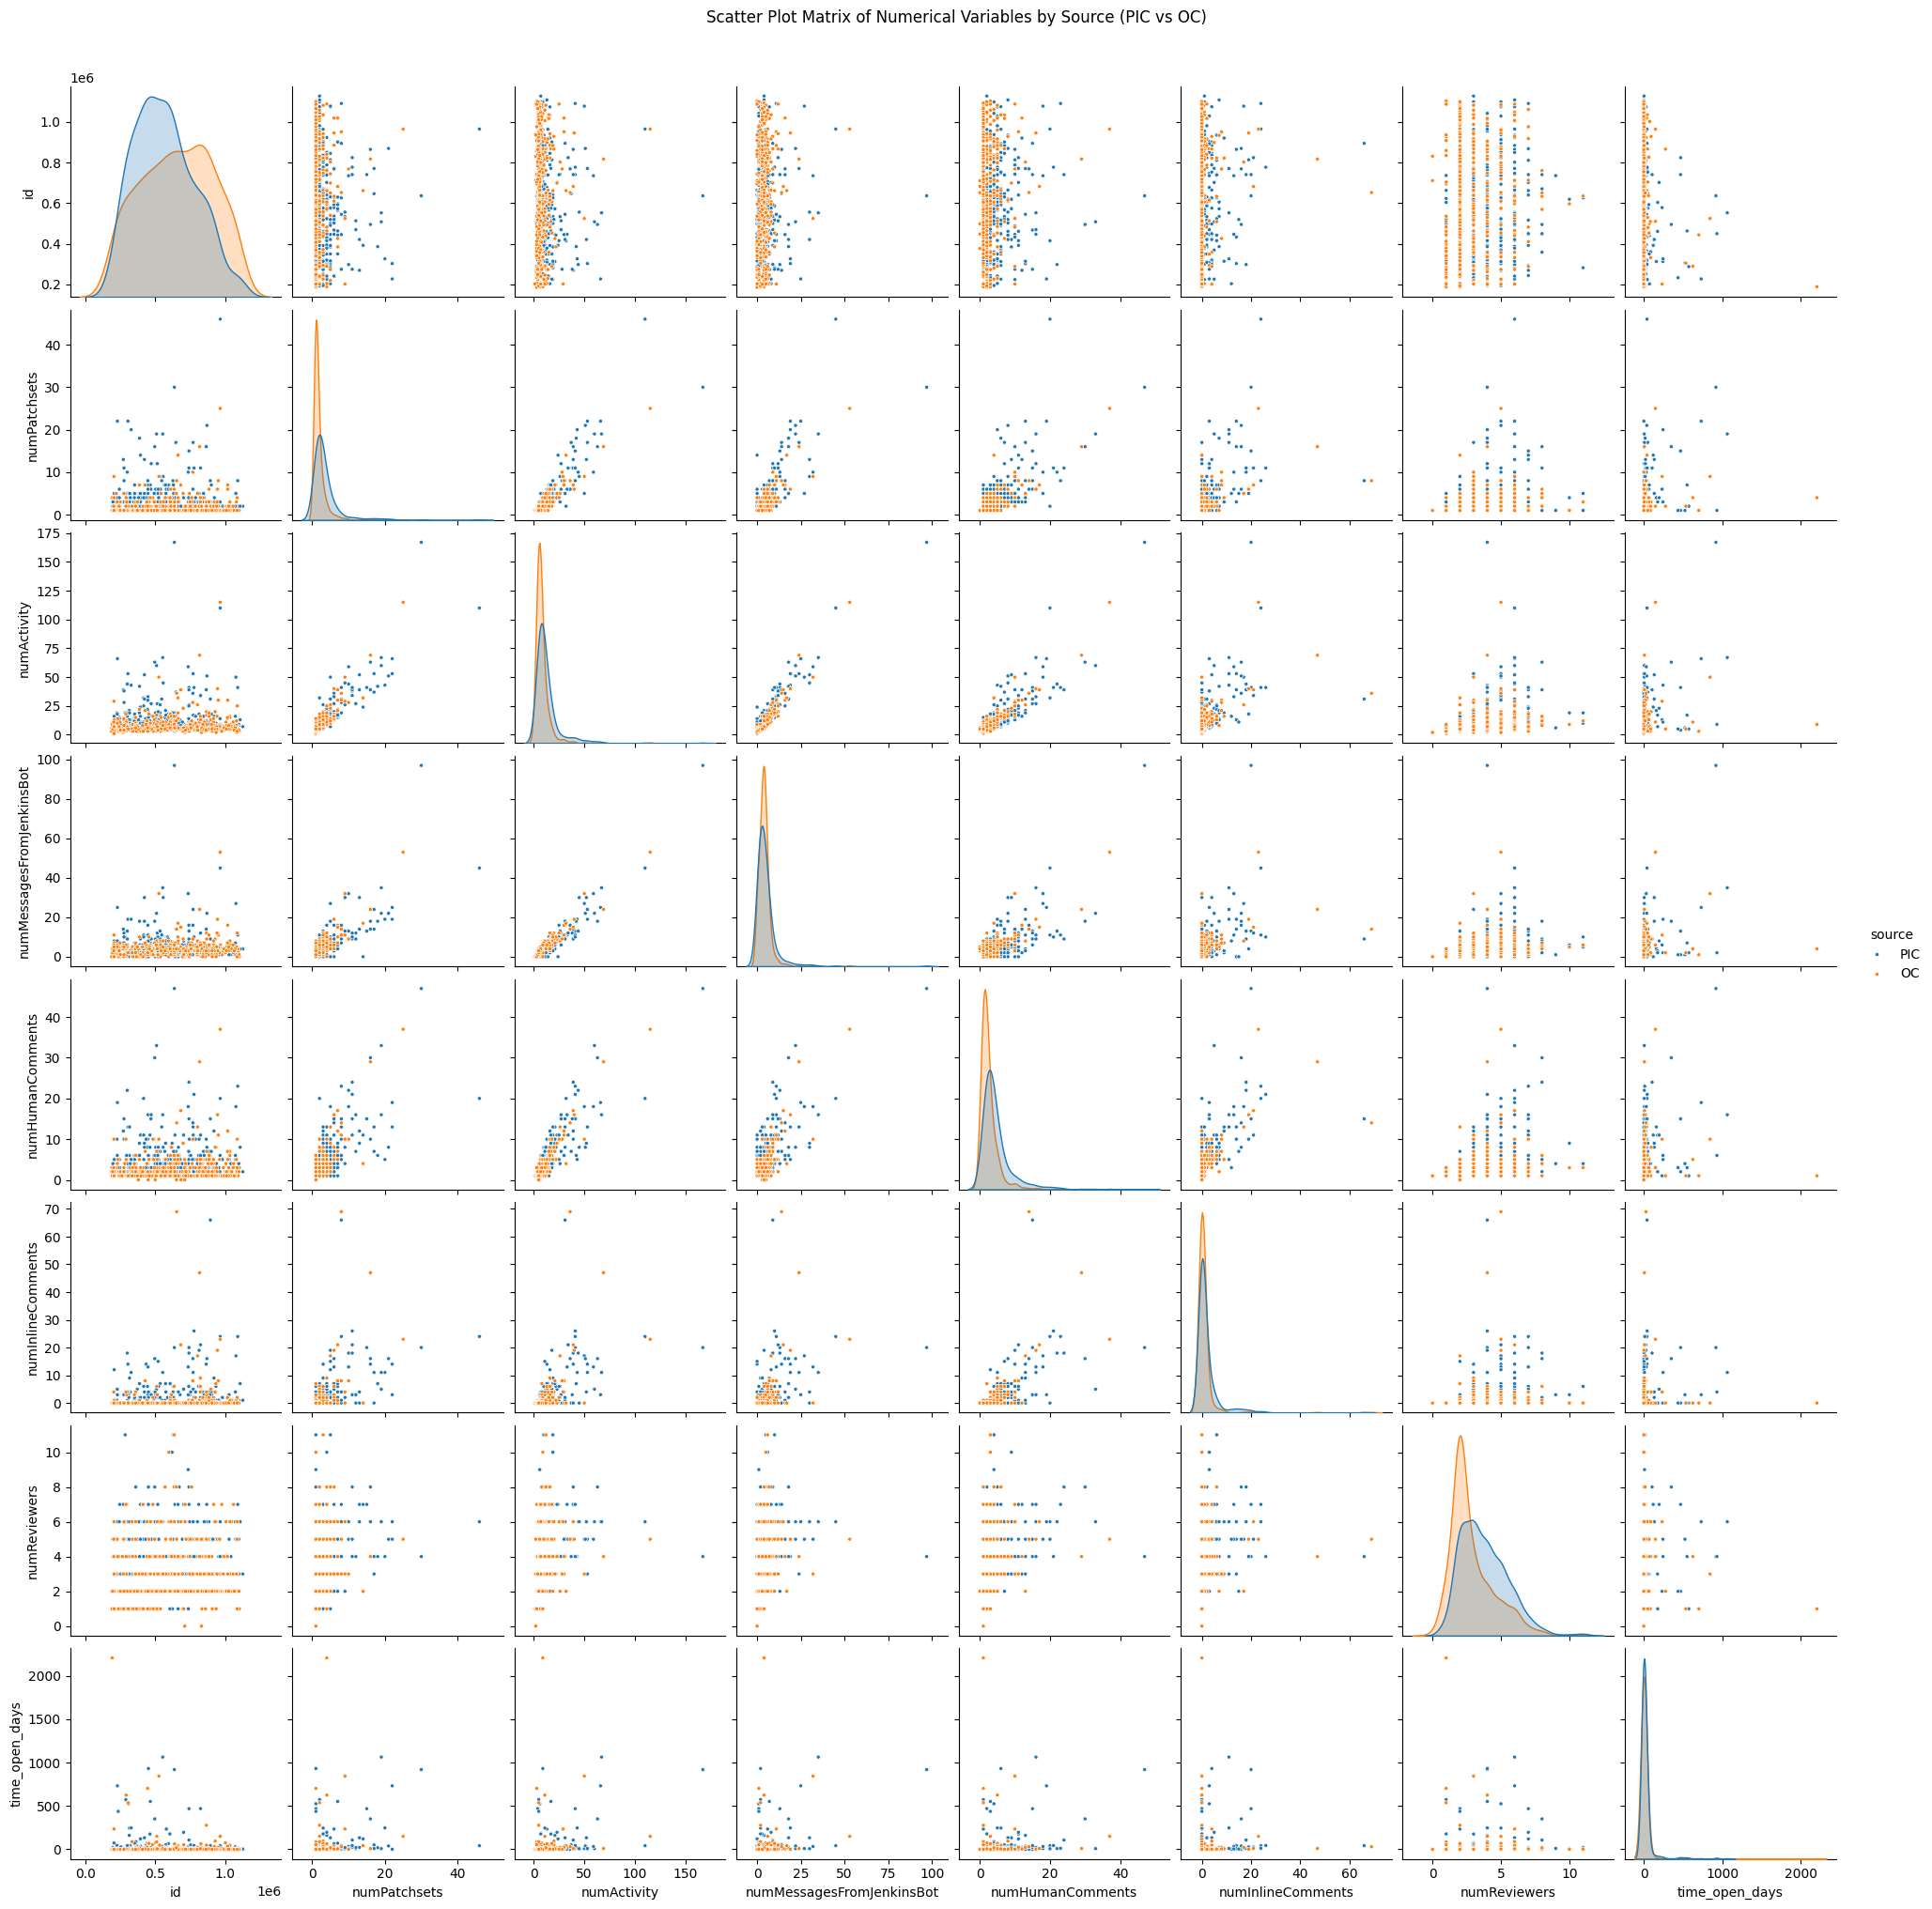

Scatter plot matrix generated.


In [ ]:
# Code Review Artifacts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Sample 400 tasks from each group if there are more than 500
sample_size = 400
if len(merged_or_abandoned_pic_crs) > sample_size:
    post_incident_crs_sampled = merged_or_abandoned_pic_crs.sample(n=sample_size, random_state=42)
else:
    post_incident_crs_sampled = merged_or_abandoned_pic_crs

if len(merged_or_abandoned_oc_crs) > sample_size:
    other_crs_sampled = merged_or_abandoned_oc_crs.sample(n=sample_size, random_state=42)
else:
    other_crs_sampled = merged_or_abandoned_oc_crs

# Combine the sampled dataframes
sampled_crs = pd.concat([post_incident_crs_sampled, other_crs_sampled])

# Create the scatter plot matrix using the selected columns and coloring by 'source'
sns.pairplot(data=sampled_crs, vars=numerical_cols_crs, hue='source', diag_kind='kde', markers='.')
plt.suptitle('Scatter Plot Matrix of Numerical Variables by Source (PIC vs OC)', y=1.02) # Add a title
plt.show()

print("Scatter plot matrix generated.")

# Figures

### Exploration: Task Histograms

Generating task histograms...


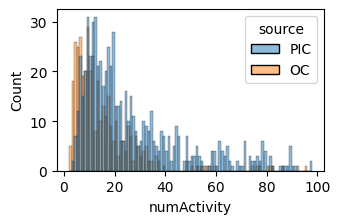

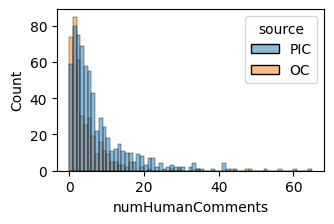

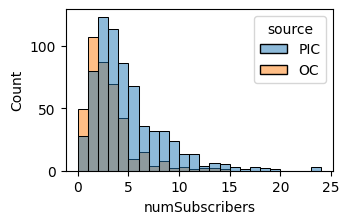

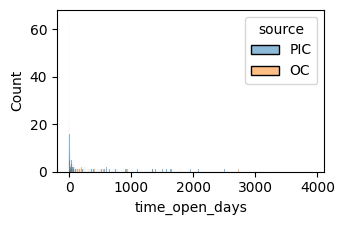

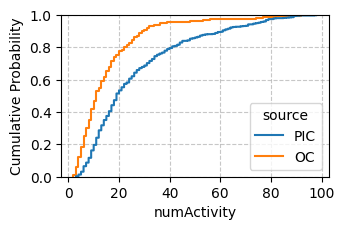

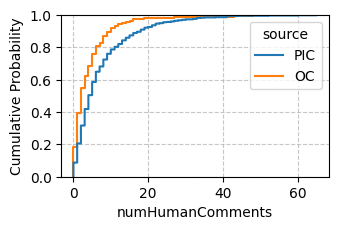

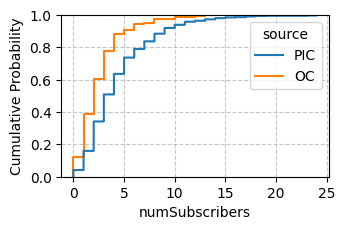

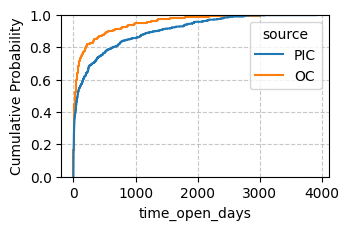

Task histograms generated.


In [ ]:
# Task Artifacts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine the full dataframes for closed tasks
sampled_tasks = pd.concat([closed_pic_tasks, closed_oc_tasks])

# Columns to plot as histograms for tasks
task_histogram_cols = ['numActivity', 'numHumanComments', 'numSubscribers']

print("Generating task histograms...")
size = (3.45, 2.1)

# Create histograms for the specified task columns, colored by 'source'
for col in task_histogram_cols:
    plt.figure(figsize=size)
    sns.histplot(data=sampled_tasks, x=col, hue='source', common_norm=False, binwidth=1)
    #plt.title(f'Distribution of {col} by Task (PIC vs OC)')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

# Create ECDF plots for the specified columns, colored by 'source'
for col in task_histogram_cols:
    plt.figure(figsize=size)
    sns.ecdfplot(data=sampled_tasks, x=col, hue='source')
    #plt.title(f'ECDF of {col} by Task (PIC vs OC)')
    plt.xlabel(col)
    plt.ylabel('Cumulative Probability')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

print("Task histograms generated.")


Generating task histograms...


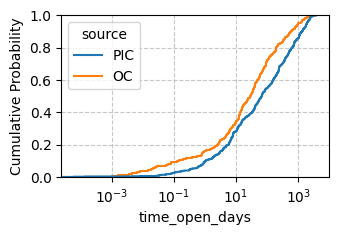

Task histograms generated.


In [ ]:
# Task Artifacts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine the full dataframes for closed tasks
sampled_tasks = pd.concat([closed_pic_tasks, closed_oc_tasks])

# Columns to plot as histograms for tasks
task_histogram_cols = ['time_open_days']

print("Generating task histograms...")
size = (3.45, 2.1)

# Create ECDF plots for the specified columns, colored by 'source'
for col in task_histogram_cols:
    plt.figure(figsize=size)
    sns.ecdfplot(data=sampled_tasks, x=col, hue='source')
    #plt.title(f'ECDF of {col} by Task (PIC vs OC)')
    plt.xlabel(col)
    plt.ylabel('Cumulative Probability')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.xscale('log') # Add this line for log scale on x-axis
    plt.show()

print("Task histograms generated.")


### Exploration: Code Review ECDF Plots

Generating ECDF plots...


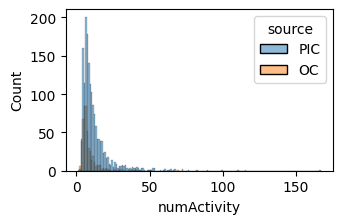

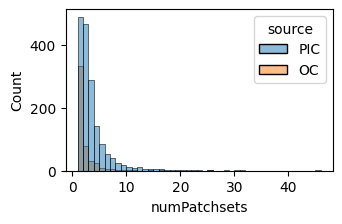

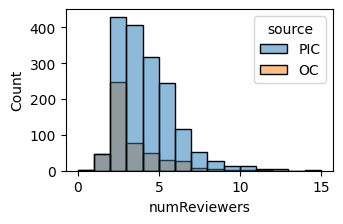

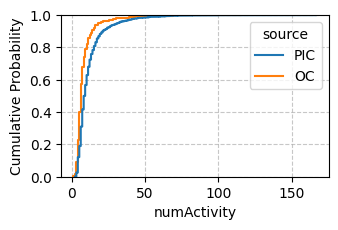

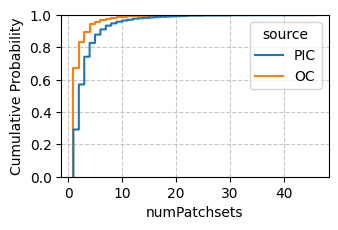

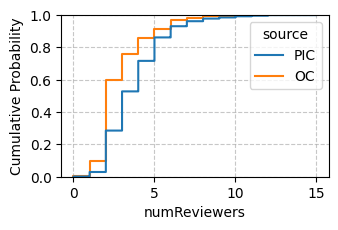

ECDF plots generated.


In [ ]:
# Code Review Artifacts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine the full dataframes (removed sampling)
sampled_crs = pd.concat([merged_or_abandoned_pic_crs, merged_or_abandoned_oc_crs])

# Columns to plot as histograms
histogram_cols = ['numActivity', 'numPatchsets', 'numReviewers']

print("Generating ECDF plots...")
size = (3.45, 2.1)

for col in histogram_cols:
    plt.figure(figsize=size)
    sns.histplot(data=sampled_crs, x=col, hue='source', common_norm=False, binwidth=1)
    #plt.title(f'Distribution of {col} by Task (PIC vs OC)')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

# Create ECDF plots for the specified columns, colored by 'source'
for col in histogram_cols:
    plt.figure(figsize=size)
    sns.ecdfplot(data=sampled_crs, x=col, hue='source')
    #plt.title(f'ECDF of {col} by Source (PIC vs OC)')
    plt.xlabel(col)
    plt.ylabel('Cumulative Probability')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

print("ECDF plots generated.")

## Task Figures

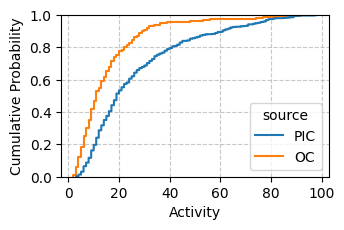

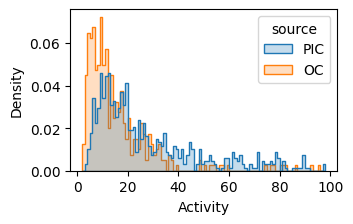

In [6]:
# Task Artifacts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine the full dataframes for closed tasks (already created)
sampled_tasks = pd.concat([closed_pic_tasks, closed_oc_tasks])


# Figures that will go in the paper

plt.figure(figsize=(3.45, 2.1))
sns.ecdfplot(data=sampled_tasks, x='numActivity', hue='source')
#plt.title(f'ECDF of Task Activity')
plt.xlabel('Activity')
plt.ylabel('Cumulative Probability')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(3.45, 2.1)) # Added figure size
sns.histplot(
    data=sampled_tasks,
    x='numActivity',
    hue='source',
    stat='density',     # Changed to density for normalization
    common_norm=False,
    binwidth=1,
    element="step",
    fill=True
)
plt.xlabel('Activity') # Added x-axis label
plt.ylabel('Density')    # Updated y-axis label to reflect density
plt.show()


--- Performing Mann-Whitney U Tests for Repo-Specific Closed Tasks (PIC vs OC) ---


--------------------------------------------------
Comparison: Puppet PIC vs Puppet OC
--------------------------------------------------

--------------------------------------------------
Mann-Whitney U Test: numActivity (Puppet PIC > Puppet OC) 
CONCLUSION: Fail to Reject the Null Hypothesis (p > 0.05). We did not find significant evidence of a difference in median numActivity.
--	 N 	Mean	Min	Q1	Med.	Q3	Max	   P-value   	r
OC	 23	35.26	  7	 14	20.00	 56	 95
PIC	224	35.29	  6	 17	27.00	 50	 98	1.8618e-01	0.0568

--------------------------------------------------
Comparison: Mediawiki-config PIC vs Mediawiki-config OC
--------------------------------------------------

--------------------------------------------------
Mann-Whitney U Test: numActivity (Mediawiki-config PIC > Mediawiki-config OC) 
CONCLUSION: Reject the Null Hypothesis (p < 0.05, U = 460.0). The median numActivity for PIC is **signif

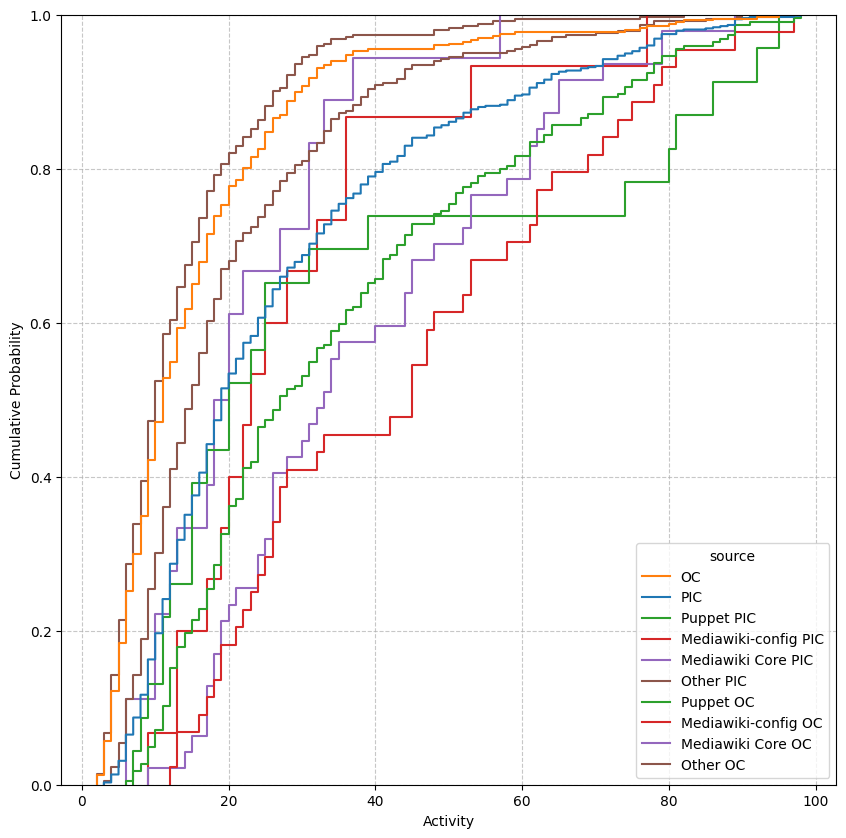

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the repository mapping file, now using 'task-repos.csv' which includes OC tasks
task_repos_df = pd.read_csv('task-repos.csv')

# Define the specific PIC repositories to plot and their display names
target_pic_repos = {
    'operations/puppet': 'Puppet PIC',
    'operations/mediawiki-config': 'Mediawiki-config PIC',
    'mediawiki/core': 'Mediawiki Core PIC'
}

# Define the specific OC repositories to plot and their display names (matching PIC)
target_oc_repos = {
    'operations/puppet': 'Puppet OC',
    'operations/mediawiki-config': 'Mediawiki-config OC',
    'mediawiki/core': 'Mediawiki Core OC'
}

# List to hold dataframes for concatenation (for plotting later)
dfs_to_concat = []

# Add PIC and OC tasks to the list. Use .copy() to ensure we are working with a separate DataFrame
# These are the overall PIC and OC tasks, *not* specific repos, but included in sampled_tasks for the existing plot
dfs_to_concat.append(closed_oc_tasks.copy())
dfs_to_concat.append(closed_pic_tasks.copy())

# Dictionary to store repo-specific dataframes for Mann-Whitney U tests
repo_specific_data = {}

# --- Process PIC Categories ---
# Keep track of all task IDs that are part of the 'specific' PIC repos
all_specific_pic_task_ids = set()

for repo_name, display_name in target_pic_repos.items():
    # Filter task_repos_df for the current repository and source 'PIC' to get relevant task IDs
    current_repo_task_ids = task_repos_df[(task_repos_df['repo'] == repo_name) & (task_repos_df['source'] == 'PIC')]['taskId']
    all_specific_pic_task_ids.update(current_repo_task_ids)

    # Filter closed_pic_tasks for these specific task IDs and create a copy
    repo_specific_pic_tasks = closed_pic_tasks[closed_pic_tasks['id'].isin(current_repo_task_ids)].copy()

    # Store for testing
    repo_specific_data[display_name] = repo_specific_pic_tasks

    # Assign the custom source label for plotting
    repo_specific_pic_tasks['source'] = display_name
    # Add to the list for concatenation
    dfs_to_concat.append(repo_specific_pic_tasks)

# Create the 'Other PIC' category
# Get all task IDs from the original closed_pic_tasks
all_pic_task_ids = set(closed_pic_tasks['id'])

# Determine 'Other PIC' task IDs by subtracting specific ones
other_pic_task_ids = list(all_pic_task_ids - all_specific_pic_task_ids)

# Filter closed_pic_tasks for these 'Other PIC' IDs
other_pic_tasks_df = closed_pic_tasks[closed_pic_tasks['id'].isin(other_pic_task_ids)].copy()
repo_specific_data['Other PIC'] = other_pic_tasks_df # Store for testing
other_pic_tasks_df['source'] = 'Other PIC' # Assign for plotting

# Add 'Other PIC' to the list for concatenation
dfs_to_concat.append(other_pic_tasks_df)

# --- Process OC Categories ---
# Keep track of all task IDs that are part of the 'specific' OC repos
all_specific_oc_task_ids = set()

for repo_name, display_name in target_oc_repos.items():
    # Filter task_repos_df for the current repository and source 'OC' to get relevant task IDs
    current_repo_task_ids = task_repos_df[(task_repos_df['repo'] == repo_name) & (task_repos_df['source'] == 'OC')]['taskId']
    all_specific_oc_task_ids.update(current_repo_task_ids)

    # Filter closed_oc_tasks for these specific task IDs and create a copy
    repo_specific_oc_tasks = closed_oc_tasks[closed_oc_tasks['id'].isin(current_repo_task_ids)].copy()

    # Store for testing
    repo_specific_data[display_name] = repo_specific_oc_tasks

    # Assign the custom source label for plotting
    repo_specific_oc_tasks['source'] = display_name
    # Add to the list for concatenation
    dfs_to_concat.append(repo_specific_oc_tasks)

# Create the 'Other OC' category
# Get all task IDs from the original closed_oc_tasks
all_oc_task_ids = set(closed_oc_tasks['id'])

# Determine 'Other OC' task IDs by subtracting specific ones
other_oc_task_ids = list(all_oc_task_ids - all_specific_oc_task_ids)

# Filter closed_oc_tasks for these 'Other OC' IDs
other_oc_tasks_df = closed_oc_tasks[closed_oc_tasks['id'].isin(other_oc_task_ids)].copy()
repo_specific_data['Other OC'] = other_oc_tasks_df # Store for testing
other_oc_tasks_df['source'] = 'Other OC' # Assign for plotting

# Add 'Other OC' to the list for concatenation
dfs_to_concat.append(other_oc_tasks_df)


# --- Mann-Whitney U Tests for Repo-Specific Closed Tasks (PIC vs OC) ---
# Assuming perform_mannwhitneyu_test is available from a previous cell.
alpha = 0.05
task_columns_to_test = ['numActivity', 'numHumanComments', 'numSubscribers', 'timeOpen', 'time_open_days']

print("\n" + "="*80)
print("--- Performing Mann-Whitney U Tests for Repo-Specific Closed Tasks (PIC vs OC) ---")
print("="*80 + "\n")

repo_pairs_to_test = [
    ('Puppet PIC', 'Puppet OC'),
    ('Mediawiki-config PIC', 'Mediawiki-config OC'),
    ('Mediawiki Core PIC', 'Mediawiki Core OC'),
    ('Other PIC', 'Other OC')
]

for pic_key, oc_key in repo_pairs_to_test:
    pic_df = repo_specific_data.get(pic_key)
    oc_df = repo_specific_data.get(oc_key)

    if pic_df is None or oc_df is None:
        print(f"\nWarning: Could not find data for {pic_key} or {oc_key}. Skipping test for this pair.")
        continue

    print(f"\n" + "-"*50)
    print(f"Comparison: {pic_key} vs {oc_key}")
    print("-" * 50)
    for col in task_columns_to_test:
        perform_mannwhitneyu_test(f'{col} ({pic_key} > {oc_key})', pic_df, oc_df, col, alternative='greater', alpha=alpha)


print("\n" + "="*80)
print("--- Performing Mann-Whitney U Tests for Overall PIC vs OC Closed Tasks ---")
print("="*80 + "\n")

for col in task_columns_to_test:
    perform_mannwhitneyu_test(f'{col} closed (PIC > OC)', closed_pic_tasks, closed_oc_tasks, col, alternative='greater', alpha=alpha)


# Combine all dataframes into sampled_tasks for plotting (existing plotting code below)
sampled_tasks = pd.concat(dfs_to_concat)

# Define custom palette to match colors for corresponding PIC and OC categories
custom_palette = {
    'PIC': 'tab:blue',
    'OC': 'tab:orange',
    'Puppet PIC': 'tab:green',
    'Puppet OC': 'tab:green',
    'Mediawiki-config PIC': 'tab:red',
    'Mediawiki-config OC': 'tab:red',
    'Mediawiki Core PIC': 'tab:purple',
    'Mediawiki Core OC': 'tab:purple',
    'Other PIC': 'tab:brown',
    'Other OC': 'tab:brown'
}

# Figures that will go in the paper

plt.figure(figsize=(10, 10))
sns.ecdfplot(data=sampled_tasks, x='numActivity', hue='source', palette=custom_palette)
#plt.title(f'ECDF of Task Activity')
plt.xlabel('Activity')
plt.ylabel('Cumulative Probability')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Code Review Effort with Per-repo breakdown

In [3]:
import pandas as pd

# Define the specific display names for PIC and OC repos (matching task definitions)
cr_pic_display_names = {
    'operations/puppet': 'Puppet PIC',
    'operations/mediawiki-config': 'Mediawiki-config PIC',
    'mediawiki/core': 'Mediawiki Core PIC'
}

cr_oc_display_names = {
    'operations/puppet': 'Puppet OC',
    'operations/mediawiki-config': 'Mediawiki-config OC',
    'mediawiki/core': 'Mediawiki Core OC'
}
# Dictionary to store repo-specific dataframes for Mann-Whitney U tests
repo_specific_cr_data = {}

# --- Process PIC Code Reviews ---
specific_pic_cr_repos_in_data = set() # To track repos for 'Other' calculation

for repo_path, display_name in cr_pic_display_names.items():
    # Filter merged_or_abandoned_pic_crs for the current repository
    repo_specific_pic_cr_df = merged_or_abandoned_pic_crs[merged_or_abandoned_pic_crs['repo'] == repo_path].copy()

    repo_specific_cr_data[display_name] = repo_specific_pic_cr_df
    specific_pic_cr_repos_in_data.add(repo_path)

# Create the 'Other PIC' category
all_pic_cr_repos_in_data = set(merged_or_abandoned_pic_crs['repo'].unique())
other_pic_cr_paths = list(all_pic_cr_repos_in_data - specific_pic_cr_repos_in_data)

other_pic_cr_df = merged_or_abandoned_pic_crs[merged_or_abandoned_pic_crs['repo'].isin(other_pic_cr_paths)].copy()
repo_specific_cr_data['Other PIC'] = other_pic_cr_df

# --- Process OC Code Reviews ---
specific_oc_cr_repos_in_data = set() # To track repos for 'Other' calculation

for repo_path, display_name in cr_oc_display_names.items():
    # Filter merged_or_abandoned_oc_crs for the current repository
    repo_specific_oc_cr_df = merged_or_abandoned_oc_crs[merged_or_abandoned_oc_crs['repo'] == repo_path].copy()

    repo_specific_cr_data[display_name] = repo_specific_oc_cr_df
    specific_oc_cr_repos_in_data.add(repo_path)

# Create the 'Other OC' category
all_oc_cr_repos_in_data = set(merged_or_abandoned_oc_crs['repo'].unique())
other_oc_cr_paths = list(all_oc_cr_repos_in_data - specific_oc_cr_repos_in_data)

other_oc_cr_df = merged_or_abandoned_oc_crs[merged_or_abandoned_oc_crs['repo'].isin(other_oc_cr_paths)].copy()
repo_specific_cr_data['Other OC'] = other_oc_cr_df


# --- Mann-Whitney U Tests for Repo-Specific Code Reviews (PIC vs OC) ---
alpha = 0.05 # Reusing alpha from previous context
cr_columns_to_test = ['numHumanComments', 'numReviewers', 'numPatchsets', 'timeOpen']

print("\n" + "="*80)
print("--- Performing Mann-Whitney U Tests for Repo-Specific Code Reviews (PIC vs OC) ---")
print("="*80 + "\n")

# Define the pairs for comparison using the consistent display names
cr_repo_pairs_to_test = [
    ('Puppet PIC', 'Puppet OC'),
    ('Mediawiki-config PIC', 'Mediawiki-config OC'),
    ('Mediawiki Core PIC', 'Mediawiki Core OC'),
    ('Other PIC', 'Other OC')
]

for pic_key, oc_key in cr_repo_pairs_to_test:
    pic_df = repo_specific_cr_data.get(pic_key)
    oc_df = repo_specific_cr_data.get(oc_key)

    if pic_df is None or oc_df is None:
        print(f"\nWarning: Could not find data for {pic_key} or {oc_key}. Skipping test for this pair.")
        continue
    if len(pic_df) == 0 or len(oc_df) == 0:
        print(f"\nWarning: Empty DataFrame for {pic_key} or {oc_key}. Skipping test for this pair.\n  PIC N={len(pic_df)}, OC N={len(oc_df)}")
        continue

    print(f"\n" + "-"*50)
    print(f"Comparison: {pic_key} vs {oc_key}")
    print("-" * 50)
    for col in cr_columns_to_test:
        perform_mannwhitneyu_test(f'{col} ({pic_key} > {oc_key})', pic_df, oc_df, col, alternative='greater', alpha=alpha)

# --- Mann-Whitney U Tests for Overall PIC vs OC Code Reviews ---
print("\n" + "="*80)
print("--- Performing Mann-Whitney U Tests for Overall PIC vs OC Merged/Abandoned Code Reviews ---")
print("="*80 + "\n")

for col in cr_columns_to_test:
    perform_mannwhitneyu_test(f'{col} merged+abandoned (PIC > OC)', merged_or_abandoned_pic_crs, merged_or_abandoned_oc_crs, col, alternative='greater', alpha=alpha)


--- Performing Mann-Whitney U Tests for Repo-Specific Code Reviews (PIC vs OC) ---


--------------------------------------------------
Comparison: Puppet PIC vs Puppet OC
--------------------------------------------------

--------------------------------------------------
Mann-Whitney U Test: numHumanComments (Puppet PIC > Puppet OC) 
CONCLUSION: Reject the Null Hypothesis (p < 0.05, U = 30939.5). The median numHumanComments for PIC is **significantly greater** than for OC.
--	 N 	Mean	Min	Q1	Med.	Q3	Max	   P-value   	r
OC	 56	3.27	  2	  2	2.00	  3	 12
PIC	867	4.62	  1	  2	3.00	  5	 41	2.1904e-04	0.1134

--------------------------------------------------
Mann-Whitney U Test: numReviewers (Puppet PIC > Puppet OC) 
CONCLUSION: Reject the Null Hypothesis (p < 0.05, U = 30462.5). The median numReviewers for PIC is **significantly greater** than for OC.
--	 N 	Mean	Min	Q1	Med.	Q3	Max	   P-value   	r
OC	 56	3.07	  1	  2	3.00	  3	  8
PIC	867	3.73	  1	  2	3.00	  5	 15	5.3182e-04	0.1053

---

# To Evolve or Not

In [ ]:
import pandas as pd
from IPython.display import display, HTML

# --- New Task Status Summary Table ---
print("\n--- Task Status Summary (PIC vs OC) ---")

status_types = ['isOpen', 'isClosed', 'isResolved', 'isDeclined', 'isDuplicate', 'isInvalid']
summary_data = {'PIC': {}, 'OC': {}}

for status_col in status_types:
    for source_name in ['PIC', 'OC']:
        total_source_tasks = len(tasks_df[tasks_df['source'] == source_name])
        if total_source_tasks > 0:
            count_status = tasks_df[(tasks_df['source'] == source_name) & (tasks_df[status_col] == True)].shape[0]
            percentage = (count_status / total_source_tasks) * 100
            summary_data[source_name][status_col] = f'{percentage:.2f}%'
        else:
            summary_data[source_name][status_col] = '0.00%'

# Calculate 'isAbandoned' column
for source_name in ['PIC', 'OC']:
    source_df = tasks_df[tasks_df['source'] == source_name]
    total_source_tasks = len(source_df)
    if total_source_tasks > 0:
        abandoned_count = source_df[(source_df['isDeclined'] == True) | \
                                    (source_df['isDuplicate'] == True) | \
                                    (source_df['isInvalid'] == True)].shape[0]
        abandoned_percentage = (abandoned_count / total_source_tasks) * 100
        summary_data[source_name]['isAbandoned'] = f'{abandoned_percentage:.2f}%'
    else:
        summary_data[source_name]['isAbandoned'] = '0.00%'

# Also add total tasks count to the summary
summary_data['PIC']['Total Tasks'] = len(tasks_df[tasks_df['source'] == 'PIC'])
summary_data['OC']['Total Tasks'] = len(tasks_df[tasks_df['source'] == 'OC'])

summary_status_df = pd.DataFrame(summary_data).T
# Reorder columns to have Total Tasks first, then status_types and isAbandoned
summary_status_df = summary_status_df[['Total Tasks'] + status_types + ['isAbandoned']]
summary_status_df.index.name = 'Source'

display(HTML(summary_status_df.to_html()))

# --- End of New Task Status Summary Table ---


# Define the desired order of priorities for consistent display
priority_order = ['Unbreak Now!', 'High', 'Medium', 'Low', 'Lowest', 'Needs Triage']

# Define the status columns for the new matrix, including 'isAbandoned'
matrix_status_cols = ['isOpen', 'isClosed', 'isResolved', 'isDeclined', 'isDuplicate', 'isInvalid', 'isAbandoned']

# Initialize a list to store data for the consolidated matrix
consolidated_priority_matrix_data = []

for priority in priority_order:
    for source in ['OC', 'PIC']:
        # Filter tasks_df for current priority and source
        current_group_df = tasks_df[(tasks_df['priority'] == priority) & (tasks_df['source'] == source)]
        total_tasks_in_group = len(current_group_df)

        row_entry = {'Priority_Source': f'{priority} ({source})'}

        # Add N column before percentages
        row_entry['N'] = total_tasks_in_group

        if total_tasks_in_group == 0:
            # If no tasks for this group, add a row of 0.00% for all status columns
            for status_col in matrix_status_cols:
                row_entry[status_col] = '0.00%'
        else:
            for status_col in matrix_status_cols:
                if status_col == 'isAbandoned':
                    # Calculate isAbandoned specifically for this group
                    count_status = current_group_df[
                        (current_group_df['isDeclined'] == True) |
                        (current_group_df['isDuplicate'] == True) |
                        (current_group_df['isInvalid'] == True)
                    ].shape[0]
                else:
                    count_status = current_group_df[current_group_df[status_col] == True].shape[0]

                percentage = (count_status / total_tasks_in_group) * 100
                row_entry[status_col] = f'{percentage:.2f}%'

        consolidated_priority_matrix_data.append(row_entry)

# Create the DataFrame from the collected data and set 'Priority_Source' as index
consolidated_priority_matrix = pd.DataFrame(consolidated_priority_matrix_data).set_index('Priority_Source')

print("\n--- Consolidated Priority Distribution Matrix by Task Status and Source ---")
display(HTML(consolidated_priority_matrix.to_html()))


--- Task Status Summary (PIC vs OC) ---


,Total Tasks,isOpen,isClosed,isResolved,isDeclined,isDuplicate,isInvalid,isAbandoned
Source,,,,,,,,
PIC,810,16.54%,83.46%,72.59%,7.41%,1.85%,1.60%,10.86%
OC,492,18.50%,81.50%,61.59%,7.11%,8.74%,4.07%,19.92%



--- Consolidated Priority Distribution Matrix by Task Status and Source ---


,N,isOpen,isClosed,isResolved,isDeclined,isDuplicate,isInvalid,isAbandoned
Priority_Source,,,,,,,,
Unbreak Now! (OC),3,0.00%,100.00%,66.67%,0.00%,33.33%,0.00%,33.33%
Unbreak Now! (PIC),30,0.00%,100.00%,96.67%,0.00%,3.33%,0.00%,3.33%
High (OC),53,5.66%,94.34%,86.79%,0.00%,5.66%,1.89%,7.55%
High (PIC),235,6.38%,93.62%,88.09%,4.26%,0.85%,0.43%,5.53%
Medium (OC),119,18.49%,81.51%,67.23%,7.56%,5.04%,1.68%,14.29%
Medium (PIC),295,21.36%,78.64%,67.12%,8.14%,1.02%,2.37%,11.53%
Low (OC),42,30.95%,69.05%,42.86%,16.67%,7.14%,2.38%,26.19%
Low (PIC),67,35.82%,64.18%,43.28%,16.42%,1.49%,2.99%,20.90%
Lowest (OC),4,0.00%,100.00%,50.00%,25.00%,25.00%,0.00%,50.00%


## Completion and Abandonment

In [ ]:
import pandas as pd
from IPython.display import display, HTML
from scipy.stats import chi2_contingency

# Ensure tasks_df is available from previous cells
if 'tasks_df' not in locals():
    print("Error: tasks_df not found. Please run previous cells to load data.")
else:
    # Initialize a dictionary to store results for each source
    results = {}

    for source_name in ['PIC', 'OC']:
        source_df = tasks_df[tasks_df['source'] == source_name]
        total_tasks_source = len(source_df)

        if total_tasks_source == 0:
            results[source_name] = {
                'Total Tasks': 0,
                'Percent Open': '0.00%',
                'Percent Closed': '0.00%',
                'Percent Resolved': '0.00%',
                'Percent Declined': '0.00%',
                'Percent Duplicate': '0.00%',
                'Percent Invalid': '0.00%',
                'Abandonment Rate (of Closed Tasks)': '0.00%'
            }
            continue

        # Calculate basic percentages
        percent_open = (source_df['isClosed'] == False).sum() / total_tasks_source * 100
        percent_closed = source_df['isClosed'].sum() / total_tasks_source * 100
        percent_resolved = source_df['isResolved'].sum() / total_tasks_source * 100
        percent_declined = source_df['isDeclined'].sum() / total_tasks_source * 100
        percent_duplicate = source_df['isDuplicate'].sum() / total_tasks_source * 100
        percent_invalid = source_df['isInvalid'].sum() / total_tasks_source * 100

        # Calculate abandonment rate (percentage of *closed* tasks that are abandoned)
        closed_tasks_source = source_df[source_df['isClosed'] == True]
        total_closed_tasks_source = len(closed_tasks_source)

        abandoned_closed_tasks_source = closed_tasks_source[
            closed_tasks_source['isDeclined'] |
            closed_tasks_source['isDuplicate'] |
            closed_tasks_source['isInvalid']
        ]
        num_abandoned_closed_tasks = len(abandoned_closed_tasks_source)

        abandonment_rate = (num_abandoned_closed_tasks / total_closed_tasks_source * 100) if total_closed_tasks_source > 0 else 0

        results[source_name] = {
            'Total Tasks': total_tasks_source,
            'Percent Open': f'{percent_open:.2f}%',
            'Percent Closed': f'{percent_closed:.2f}%',
            'Percent Resolved': f'{percent_resolved:.2f}%',
            'Percent Declined': f'{percent_declined:.2f}%',
            'Percent Duplicate': f'{percent_duplicate:.2f}%',
            'Percent Invalid': f'{percent_invalid:.2f}%',
            'Abandonment Rate (of Closed Tasks)': f'{abandonment_rate:.2f}%'
        }

    # Convert results to a DataFrame for display
    summary_df = pd.DataFrame.from_dict(results, orient='index')
    summary_df.index.name = 'Source'

    print("\n--- Task Status Summary (PIC vs OC) ---")
    display(HTML(summary_df.to_html()))

    # --- Chi-Square Test for Open vs. Closed Tasks ---
    print("\n--- Chi-Square Test for Open vs. Closed Task Status (PIC vs OC) ---")

    # Create a contingency table for 'isOpen' (derived from 'isClosed') status
    # Count of 'isOpen' (isClosed == False) and 'isClosed' (isClosed == True) for each source
    # We'll use the counts of True and False from 'isClosed'
    contingency_data = {
        'Open': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isClosed'] == False)].shape[0],
                 tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isClosed'] == False)].shape[0]],
        'Closed': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isClosed'] == True)].shape[0],
                   tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isClosed'] == True)].shape[0]]
    }
    chi_square_table = pd.DataFrame(contingency_data, index=['PIC', 'OC'])

    print("Contingency Table (Open/Closed Tasks):")
    print(chi_square_table)

    # Perform the Chi-Square test
    chi2_stat, p_value, dof, expected = chi2_contingency(chi_square_table)

    print(f"\nChi-Square Statistic: {chi2_stat:.2f}")
    print(f"P-value: {p_value:.4e}")
    print(f"Degrees of Freedom: {dof}")

    alpha = 0.05
    if p_value < alpha:
        print(f"\nCONCLUSION: Reject the Null Hypothesis (p < {alpha}). There is a statistically significant difference in the distribution of open/closed task statuses between PIC and OC.")
    else:
        print(f"\nCONCLUSION: Fail to Reject the Null Hypothesis (p > {alpha}). There is no statistically significant difference in the distribution of open/closed task statuses between PIC and OC.")



--- Task Status Summary (PIC vs OC) ---


,Total Tasks,Percent Open,Percent Closed,Percent Resolved,Percent Declined,Percent Duplicate,Percent Invalid,Abandonment Rate (of Closed Tasks)
Source,,,,,,,,
PIC,810,16.54%,83.46%,72.59%,7.41%,1.85%,1.60%,13.02%
OC,492,18.50%,81.50%,61.59%,7.11%,8.74%,4.07%,24.44%



--- Chi-Square Test for Open vs. Closed Task Status (PIC vs OC) ---
Contingency Table (Open/Closed Tasks):
     Open  Closed
PIC   134     676
OC     91     401

Chi-Square Statistic: 0.69
P-value: 4.0767e-01
Degrees of Freedom: 1

CONCLUSION: Fail to Reject the Null Hypothesis (p > 0.05). There is no statistically significant difference in the distribution of open/closed task statuses between PIC and OC.


## Chi-Square Test for Resolved Task Rates

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# Ensure tasks_df is available from previous cells
if 'tasks_df' not in locals():
    print("Error: tasks_df not found. Please run previous cells to load data.")
else:
    # Create a contingency table for 'isResolved' status
    # Count of 'isResolved' (True) and 'Not Resolved' (False) for each source
    contingency_data_resolved = {
        'Resolved': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isResolved'] == True)].shape[0],
                     tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isResolved'] == True)].shape[0]],
        'Not Resolved': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isResolved'] == False)].shape[0],
                         tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isResolved'] == False)].shape[0]]
    }
    chi_square_table_resolved = pd.DataFrame(contingency_data_resolved, index=['PIC', 'OC'])

    print("--- Contingency Table (Source vs. Resolved Tasks) ---")
    print(chi_square_table_resolved)
    print("\n")

    # Perform the Chi-Square test
    chi2_stat_resolved, p_value_resolved, dof_resolved, expected_resolved = chi2_contingency(chi_square_table_resolved)

    print("--- Chi-Square Test Results for Resolved Tasks ---")
    print(f"Chi-Square Statistic: {chi2_stat_resolved:.2f}")
    print(f"P-value: {p_value_resolved:.4e}")
    print(f"Degrees of Freedom: {dof_resolved}")

    alpha = 0.05
    if p_value_resolved < alpha:
        print(f"\nCONCLUSION: Reject the Null Hypothesis (p < {alpha}). There is a statistically significant difference in the resolution rates between PIC and OC tasks.")
        # Further interpretation based on observed percentages
        pic_resolved_rate = (tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isResolved'] == True)].shape[0] / tasks_df[tasks_df['source'] == 'PIC'].shape[0]) * 100
        oc_resolved_rate = (tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isResolved'] == True)].shape[0] / tasks_df[tasks_df['source'] == 'OC'].shape[0]) * 100
        if pic_resolved_rate > oc_resolved_rate:
            print(f"Specifically, PIC tasks ({pic_resolved_rate:.2f}%) are resolved at a significantly higher rate than OC tasks ({oc_resolved_rate:.2f}%).")
        else:
            print(f"Specifically, OC tasks ({oc_resolved_rate:.2f}%) are resolved at a significantly higher rate than PIC tasks ({pic_resolved_rate:.2f}%).")
    else:
        print(f"\nCONCLUSION: Fail to Reject the Null Hypothesis (p > {alpha}). There is no statistically significant difference in the resolution rates between PIC and OC tasks.")


--- Contingency Table (Source vs. Resolved Tasks) ---
     Resolved  Not Resolved
PIC       588           222
OC        303           189


--- Chi-Square Test Results for Resolved Tasks ---
Chi-Square Statistic: 16.66
P-value: 4.4682e-05
Degrees of Freedom: 1

CONCLUSION: Reject the Null Hypothesis (p < 0.05). There is a statistically significant difference in the resolution rates between PIC and OC tasks.
Specifically, PIC tasks (72.59%) are resolved at a significantly higher rate than OC tasks (61.59%).


## Chi-Square Test for Duplicate and Invalid Task Rates

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# Ensure tasks_df is available from previous cells
if 'tasks_df' not in locals():
    print("Error: tasks_df not found. Please run previous cells to load data.")
else:
    # --- Chi-Square Test for isDuplicate Tasks ---
    print("\n--- Chi-Square Test for Duplicate Task Rates ---")
    contingency_data_duplicate = {
        'Duplicate': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isDuplicate'] == True)].shape[0],
                      tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isDuplicate'] == True)].shape[0]],
        'Not Duplicate': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isDuplicate'] == False)].shape[0],
                          tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isDuplicate'] == False)].shape[0]]
    }
    chi_square_table_duplicate = pd.DataFrame(contingency_data_duplicate, index=['PIC', 'OC'])

    print("Contingency Table (Source vs. Duplicate Tasks):")
    print(chi_square_table_duplicate)

    chi2_stat_duplicate, p_value_duplicate, dof_duplicate, expected_duplicate = chi2_contingency(chi_square_table_duplicate)

    print(f"\nChi-Square Statistic: {chi2_stat_duplicate:.2f}")
    print(f"P-value: {p_value_duplicate:.4e}")
    print(f"Degrees of Freedom: {dof_duplicate}")

    alpha = 0.05
    if p_value_duplicate < alpha:
        print(f"\nCONCLUSION: Reject the Null Hypothesis (p < {alpha}). There is a statistically significant difference in the rates of duplicate tasks between PIC and OC.")
        pic_duplicate_rate = (tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isDuplicate'] == True)].shape[0] / len(tasks_df[tasks_df['source'] == 'PIC'])) * 100
        oc_duplicate_rate = (tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isDuplicate'] == True)].shape[0] / len(tasks_df[tasks_df['source'] == 'OC'])) * 100
        if oc_duplicate_rate > pic_duplicate_rate:
            print(f"Specifically, OC tasks ({oc_duplicate_rate:.2f}%) are more often marked as duplicate than PIC tasks ({pic_duplicate_rate:.2f}%).")
        else:
            print(f"Specifically, PIC tasks ({pic_duplicate_rate:.2f}%) are more often marked as duplicate than OC tasks ({oc_duplicate_rate:.2f}%).")
    else:
        print(f"\nCONCLUSION: Fail to Reject the Null Hypothesis (p > {alpha}). There is no statistically significant difference in the rates of duplicate tasks between PIC and OC.")

    # --- Chi-Square Test for isInvalid Tasks ---
    print("\n--- Chi-Square Test for Invalid Task Rates ---")
    contingency_data_invalid = {
        'Invalid': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isInvalid'] == True)].shape[0],
                    tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isInvalid'] == True)].shape[0]],
        'Not Invalid': [tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isInvalid'] == False)].shape[0],
                        tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isInvalid'] == False)].shape[0]]
    }
    chi_square_table_invalid = pd.DataFrame(contingency_data_invalid, index=['PIC', 'OC'])

    print("Contingency Table (Source vs. Invalid Tasks):")
    print(chi_square_table_invalid)

    chi2_stat_invalid, p_value_invalid, dof_invalid, expected_invalid = chi2_contingency(chi_square_table_invalid)

    print(f"\nChi-Square Statistic: {chi2_stat_invalid:.2f}")
    print(f"P-value: {p_value_invalid:.4e}")
    print(f"Degrees of Freedom: {dof_invalid}")

    alpha = 0.05
    if p_value_invalid < alpha:
        print(f"\nCONCLUSION: Reject the Null Hypothesis (p < {alpha}). There is a statistically significant difference in the rates of invalid tasks between PIC and OC.")
        pic_invalid_rate = (tasks_df[(tasks_df['source'] == 'PIC') & (tasks_df['isInvalid'] == True)].shape[0] / len(tasks_df[tasks_df['source'] == 'PIC'])) * 100
        oc_invalid_rate = (tasks_df[(tasks_df['source'] == 'OC') & (tasks_df['isInvalid'] == True)].shape[0] / len(tasks_df[tasks_df['source'] == 'OC'])) * 100
        if oc_invalid_rate > pic_invalid_rate:
            print(f"Specifically, OC tasks ({oc_invalid_rate:.2f}%) are more often marked as invalid than PIC tasks ({pic_invalid_rate:.2f}%).")
        else:
            print(f"Specifically, PIC tasks ({pic_invalid_rate:.2f}%) are more often marked as invalid than OC tasks ({oc_invalid_rate:.2f}%).")
    else:
        print(f"\nCONCLUSION: Fail to Reject the Null Hypothesis (p > {alpha}). There is no statistically significant difference in the rates of invalid tasks between PIC and OC.")



--- Chi-Square Test for Duplicate Task Rates ---
Contingency Table (Source vs. Duplicate Tasks):
     Duplicate  Not Duplicate
PIC         15            795
OC          43            449

Chi-Square Statistic: 32.52
P-value: 1.1798e-08
Degrees of Freedom: 1

CONCLUSION: Reject the Null Hypothesis (p < 0.05). There is a statistically significant difference in the rates of duplicate tasks between PIC and OC.
Specifically, OC tasks (8.74%) are more often marked as duplicate than PIC tasks (1.85%).

--- Chi-Square Test for Invalid Task Rates ---
Contingency Table (Source vs. Invalid Tasks):
     Invalid  Not Invalid
PIC       13          797
OC        20          472

Chi-Square Statistic: 6.54
P-value: 1.0571e-02
Degrees of Freedom: 1

CONCLUSION: Reject the Null Hypothesis (p < 0.05). There is a statistically significant difference in the rates of invalid tasks between PIC and OC.
Specifically, OC tasks (4.07%) are more often marked as invalid than PIC tasks (1.60%).


## Code Review Abandonment

In [ ]:
import pandas as pd
from IPython.display import display, HTML

print("--- Code Review Abandonment Rates (PIC vs OC) ---")

# Ensure crs_df is available from previous cells
if 'crs_df' not in locals():
    print("Error: crs_df not found. Please run previous cells to load data.")
else:
    results = {}
    sources = ['PIC', 'OC', 'Overall']

    for source_name in sources:
        if source_name == 'Overall':
            filtered_df = crs_df
        else:
            filtered_df = crs_df[crs_df['source'] == source_name]

        total_crs_source = len(filtered_df)

        if total_crs_source == 0:
            results[source_name] = {
                'Total Code Reviews': 0,
                'Abandoned Count': 0,
                'Merged Count': 0,
                'New Count': 0,
                'Abandoned %': '0.00%',
                'Merged %': '0.00%',
                'New %': '0.00%' # Added New % initialization
            }
            continue

        abandoned_crs = filtered_df[filtered_df['status'] == 'ABANDONED']
        merged_crs = filtered_df[filtered_df['status'] == 'MERGED']
        new_crs = filtered_df[filtered_df['status'] == 'NEW']

        abandoned_count = len(abandoned_crs)
        merged_count = len(merged_crs)
        new_count = len(new_crs)

        # Calculate abandonment rate based on all code reviews that are not 'NEW'
        total_actioned_crs = total_crs_source - new_count

        abandonment_rate = (abandoned_count / total_actioned_crs * 100) if total_actioned_crs > 0 else 0
        merged_percentage = (merged_count / total_actioned_crs * 100) if total_actioned_crs > 0 else 0
        new_percentage = (new_count / total_crs_source * 100) if total_crs_source > 0 else 0 # Calculate New %

        results[source_name] = {
            'Total Code Reviews': total_crs_source,
            'Abandoned Count': abandoned_count,
            'Merged Count': merged_count,
            'New Count': new_count,
            'Abandoned %': f'{abandonment_rate:.2f}%',
            'Merged %': f'{merged_percentage:.2f}%',
            'New %': f'{new_percentage:.2f}%' # Added New % to results
        }

    summary_df = pd.DataFrame.from_dict(results, orient='index')
    summary_df.index.name = 'Source'

    display(HTML(summary_df.to_html()))

--- Code Review Abandonment Rates (PIC vs OC) ---


,Total Code Reviews,Abandoned Count,Merged Count,New Count,Abandoned %,Merged %,New %
Source,,,,,,,
PIC,1703,128,1547,28,7.64%,92.36%,1.64%
OC,500,35,461,4,7.06%,92.94%,0.80%
Overall,2203,163,2008,32,7.51%,92.49%,1.45%


## Chi-Square Test of Independence for Code Review Statuses

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# Ensure crs_df is available from previous cells
if 'crs_df' not in locals():
    print("Error: crs_df not found. Please run previous cells to load data.")
else:
    processed_crs_df = crs_df.copy()

    # Define final status for code reviews
    def determine_cr_status(row):
        if row['status'] == 'ABANDONED':
            return 'Abandoned'
        elif row['status'] == 'MERGED':
            return 'Merged'
        elif row['status'] == 'NEW':
            return 'New'
        return 'Unknown'

    processed_crs_df['final_cr_status'] = processed_crs_df.apply(determine_cr_status, axis=1)

    # Create a contingency table
    # We are comparing 'source' (PIC/OC) against 'final_cr_status'
    contingency_table_cr = pd.crosstab(processed_crs_df['source'], processed_crs_df['final_cr_status'])

    print("--- Contingency Table (Source vs. Code Review Status) ---")
    print(contingency_table_cr)
    print("\n")

    # Perform the Chi-Square test of independence
    chi2_cr, p_value_cr, dof_cr, expected_cr = chi2_contingency(contingency_table_cr)

    print("--- Chi-Square Test Results for Code Reviews ---")
    print(f"Chi-Square Statistic: {chi2_cr:.2f}")
    print(f"P-value: {p_value_cr:.4e}")
    print(f"Degrees of Freedom: {dof_cr}")

    # Interpret the results
    alpha = 0.05
    if p_value_cr < alpha:
        print(f"\nCONCLUSION: Reject the Null Hypothesis (p < {alpha}). There is a statistically significant difference in the distribution of code review statuses between PIC and OC.")
    else:
        print(f"\nCONCLUSION: Fail to Reject the Null Hypothesis (p > {alpha}). There is no statistically significant difference in the distribution of code review statuses between PIC and OC.")


--- Contingency Table (Source vs. Code Review Status) ---
final_cr_status  Abandoned  Merged  New
source                                 
OC                      35     461    4
PIC                    128    1547   28


--- Chi-Square Test Results for Code Reviews ---
Chi-Square Statistic: 2.11
P-value: 3.4753e-01
Degrees of Freedom: 2

CONCLUSION: Fail to Reject the Null Hypothesis (p > 0.05). There is no statistically significant difference in the distribution of code review statuses between PIC and OC.


## Task Priorities

In [ ]:
# Don't count other because those are private tasks


# Calculate counts and percentages for initial priority
pic_initial_priority_counts = pic_tasks['initialPriority'].value_counts()
oc_initial_priority_counts = oc_tasks['initialPriority'].value_counts()
pic_initial_priority_percentage = (pic_initial_priority_counts / len(pic_tasks)) * 100
oc_initial_priority_percentage = (oc_initial_priority_counts / len(oc_tasks)) * 100

# Calculate counts and percentages for ending priority
pic_ending_priority_counts = pic_tasks['priority'].value_counts()
oc_ending_priority_counts = oc_tasks['priority'].value_counts()
pic_ending_priority_percentage = (pic_ending_priority_counts / len(pic_tasks)) * 100
oc_ending_priority_percentage = (oc_ending_priority_counts / len(oc_tasks)) * 100

from IPython.display import display, HTML

# Define the desired order of priorities
priority_order = ['Unbreak Now!', 'High', 'Medium', 'Low', 'Lowest', 'Needs Triage', 'other']

def formatCell(count, perc):
  #return f"{int(count)} ({perc:.2f}%)"
  return f"{perc:.2f}%"

# Combine counts and percentages and format as strings, reindexing and filling missing values
initial_priority_combined_oc = oc_initial_priority_counts.combine(oc_initial_priority_percentage, formatCell).reindex(priority_order).fillna('0.00%')
initial_priority_combined_pic = pic_initial_priority_counts.combine(pic_initial_priority_percentage, formatCell).reindex(priority_order).fillna('0.00%')
ending_priority_combined_oc = oc_ending_priority_counts.combine(oc_ending_priority_percentage, formatCell).reindex(priority_order).fillna('0.00%')
ending_priority_combined_pic = pic_ending_priority_counts.combine(pic_ending_priority_percentage, formatCell).reindex(priority_order).fillna('0.00%')


# Convert Series to DataFrames and concatenate for HTML display
initial_priority_df = pd.concat([initial_priority_combined_oc.rename('OC'), initial_priority_combined_pic.rename('PIC')], axis=1)
ending_priority_df = pd.concat([ending_priority_combined_oc.rename('OC'), ending_priority_combined_pic.rename('PIC')], axis=1)

# Calculate totals and add a total row
initial_total_oc = len(oc_tasks)
initial_total_pic = len(pic_tasks)
ending_total_oc = len(oc_tasks)
ending_total_pic = len(pic_tasks)

initial_priority_df.loc['Total'] = [f"{initial_total_oc}", f"{initial_total_pic}"]
ending_priority_df.loc['Total'] = [f"{ending_total_oc}", f"{ending_total_pic}"]


print("Initial Priority Distribution (Percentage):")
display(HTML(initial_priority_df.to_html()))

print("\nEnding Priority Distribution (Percentage):")
display(HTML(ending_priority_df.to_html()))

print("\nUnique Initial Priority categories in tasks:")
print(tasks_df['initialPriority'].unique())

print("\nUnique Ending Priority categories in tasks:")
print(tasks_df['priority'].unique())

Initial Priority Distribution (Percentage):


,OC,PIC
initialPriority,,
Unbreak Now!,0.61%,4.81%
High,11.38%,26.91%
Medium,22.56%,34.20%
Low,7.11%,5.80%
Lowest,0.61%,0.49%
Needs Triage,57.72%,27.78%
other,0.00%,0.00%
Total,492,810



Ending Priority Distribution (Percentage):


,OC,PIC
priority,,
Unbreak Now!,0.61%,3.70%
High,10.77%,29.01%
Medium,24.19%,36.42%
Low,8.54%,8.27%
Lowest,0.81%,0.74%
Needs Triage,55.08%,21.85%
other,0.00%,0.00%
Total,492,810



Unique Initial Priority categories in tasks:
['Needs Triage' 'High' 'Medium' 'Low' 'Lowest' 'Unbreak Now!']

Unique Ending Priority categories in tasks:
['Needs Triage' 'High' 'Lowest' 'Medium' 'Low' 'Unbreak Now!']


## Priority and Time to Resolve

In [ ]:
# Define the desired order of priorities for consistent display (re-defined for cell independence)
priority_order = ['Unbreak Now!', 'High', 'Medium', 'Low', 'Lowest', 'Needs Triage']

print("Median time open for resolved tasks by priority level:")
print("-" * 60)

for priority in priority_order:
    pic_tasks_by_priority = closed_pic_tasks[closed_pic_tasks['priority'] == priority]
    oc_tasks_by_priority = closed_oc_tasks[closed_oc_tasks['priority'] == priority]

    median_time_open_pic = pic_tasks_by_priority['timeOpen'].median()
    median_time_open_oc = oc_tasks_by_priority['timeOpen'].median()

    print(f"Priority: {priority}")
    if not pd.isna(median_time_open_pic):
        print(f"  PIC (N={len(pic_tasks_by_priority)}): {format_ms_nicely(median_time_open_pic)}")
    else:
        print(f"  PIC (N={len(pic_tasks_by_priority)}): No data")

    if not pd.isna(median_time_open_oc):
        print(f"  OC (N={len(oc_tasks_by_priority)}): {format_ms_nicely(median_time_open_oc)}")
    else:
        print(f"  OC (N={len(oc_tasks_by_priority)}): No data")
    print("-" * 60)

Median time open for resolved tasks by priority level:
------------------------------------------------------------
Priority: Unbreak Now!
  PIC (N=30): 12.0 hours
  OC (N=3): 18.7 hours
------------------------------------------------------------
Priority: High
  PIC (N=220): 1.4 months
  OC (N=50): 26.5 days
------------------------------------------------------------
Priority: Medium
  PIC (N=232): 7.9 months
  OC (N=97): 1.7 months
------------------------------------------------------------
Priority: Low
  PIC (N=43): 1.1 years
  OC (N=29): 7.4 months
------------------------------------------------------------
Priority: Lowest
  PIC (N=5): 4.8 months
  OC (N=4): 6.6 months
------------------------------------------------------------
Priority: Needs Triage
  PIC (N=146): 16.5 days
  OC (N=218): 18.3 days
------------------------------------------------------------


# [unused] Task Heatmap

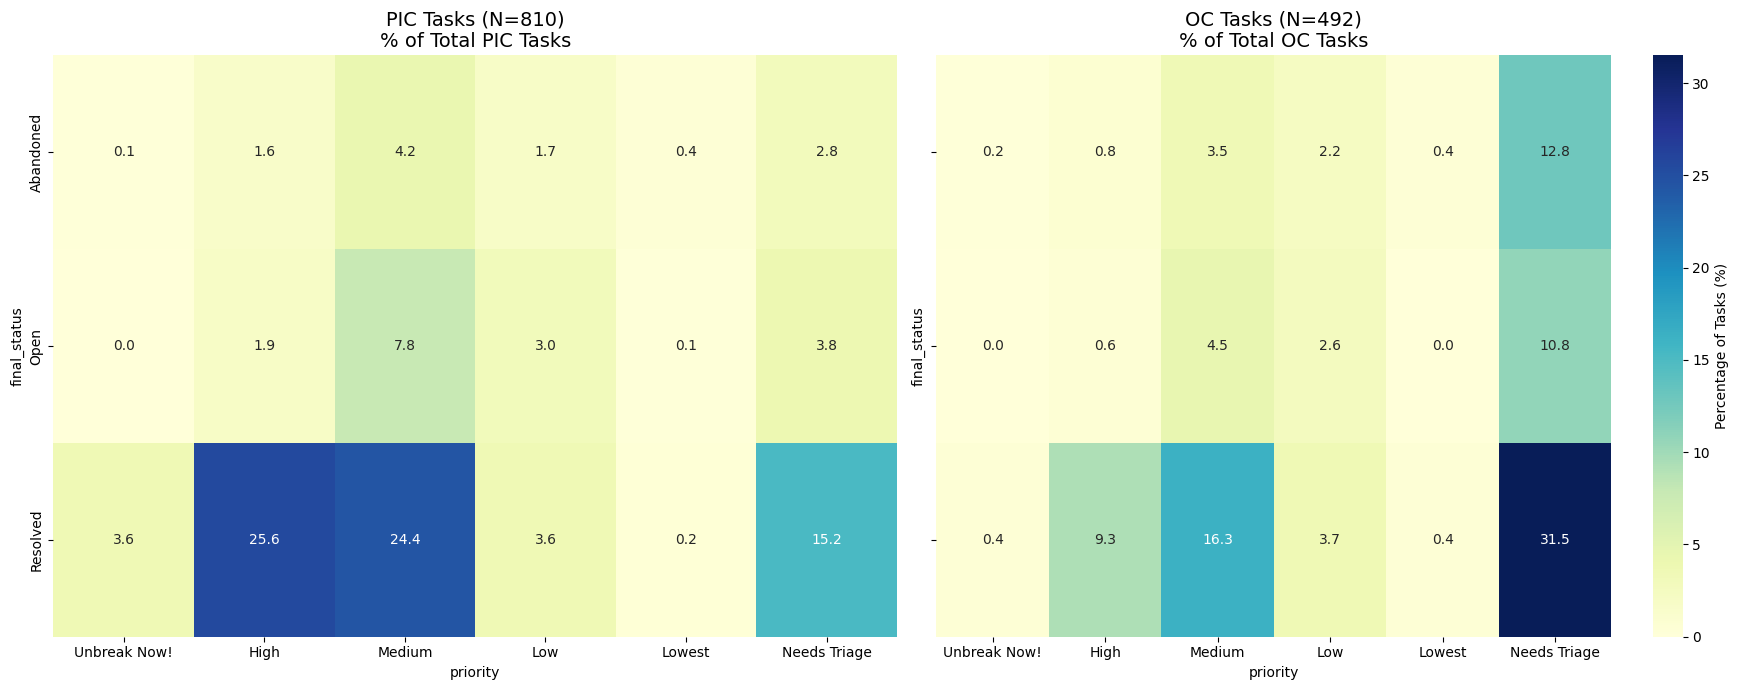

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define the Priority Order (Ordinal)
priority_order = ["Unbreak Now!", "High", "Medium", "Low", "Lowest", "Needs Triage"]

def preprocess_jira_data(df):
    # Create a copy to avoid SettingWithCopy warnings
    temp_df = df.copy()

    # 2. Derive the 'Abandoned' status and consolidate into one column
    # Priority of logic: Abandoned -> Resolved -> Open -> Closed
    def determine_status(row):
        if row['isDeclined'] or row['isDuplicate'] or row['isInvalid']:
            return 'Abandoned'
        if row['isResolved']:
            return 'Resolved'
        if row['isOpen']:
            return 'Open'
        if row['isClosed']:
            return 'Closed'
        return 'Unknown'

    temp_df['final_status'] = temp_df.apply(determine_status, axis=1)

    # Ensure Priority is a categorical type with the correct order
    temp_df['priority'] = pd.Categorical(temp_df['priority'], categories=priority_order, ordered=True)

    return temp_df

# Process your variables
pic_processed = preprocess_jira_data(pic_tasks)
oc_processed = preprocess_jira_data(oc_tasks)

# 3. Calculate Percentages (Normalization)
def get_heatmap_data(df):
    # Group by Status and Priority, count them, and divide by total samples in that group
    counts = df.groupby(['final_status', 'priority'], observed=False).size().unstack(fill_value=0)
    percentage = (counts / len(df)) * 100
    return percentage

pic_pivot = get_heatmap_data(pic_processed)
oc_pivot = get_heatmap_data(oc_processed)

# 4. Plotting
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# We find the max percentage across both to keep the color scale consistent
vmax = max(pic_pivot.max().max(), oc_pivot.max().max())

# Heatmap for PIC Tasks (Group A)
sns.heatmap(pic_pivot, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0],
            vmin=0, vmax=vmax, cbar=False)
axes[0].set_title(f'PIC Tasks (N={len(pic_tasks)})\n% of Total PIC Tasks', fontsize=14)

# Heatmap for OC Tasks (Group B)
sns.heatmap(oc_pivot, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1],
            vmin=0, vmax=vmax, cbar_kws={'label': 'Percentage of Tasks (%)'})
axes[1].set_title(f'OC Tasks (N={len(oc_tasks)})\n% of Total OC Tasks', fontsize=14)

plt.tight_layout()
plt.show()

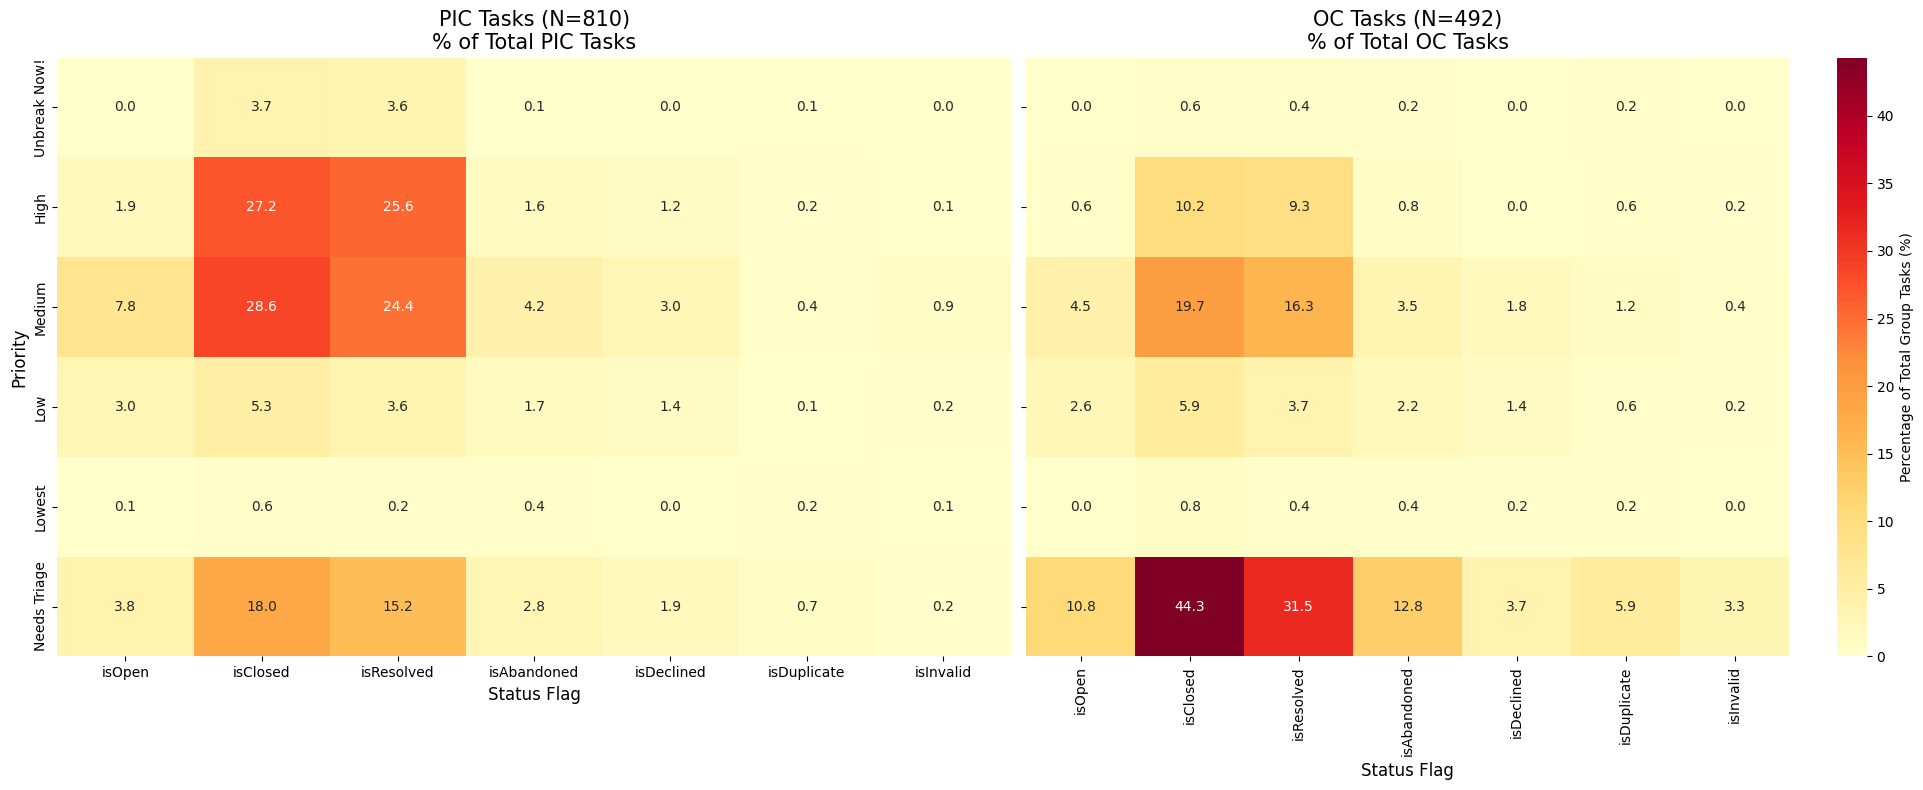

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuration
priority_order = ["Unbreak Now!", "High", "Medium", "Low", "Lowest", "Needs Triage"]
status_columns = ['isOpen', 'isClosed', 'isResolved', 'isAbandoned', 'isDeclined', 'isDuplicate', 'isInvalid']

def get_status_priority_matrix(df, group_total):
    # Ensure isAbandoned is derived correctly
    df = df.copy()
    df['isAbandoned'] = df['isDeclined'] | df['isDuplicate'] | df['isInvalid']

    # Create a container for our results
    matrix_data = []

    # Calculate percentages for each status flag independently
    for status in status_columns:
        # Group by priority and sum the booleans (which gives the count)
        counts = df.groupby('priority', observed=False)[status].sum()
        # Normalize by the total number of tasks in the group (e.g., 810 or 492)
        percentages = (counts / group_total) * 100
        matrix_data.append(percentages)

    # Combine into a DataFrame: Rows = Priority, Columns = Status
    res_df = pd.concat(matrix_data, axis=1)
    res_df.columns = status_columns

    # Reindex to ensure priorities are in the right order on the Y-axis
    return res_df.reindex(priority_order)

# 2. Process both groups
# We use the total count of tasks in each group to normalize fairly
pic_matrix = get_status_priority_matrix(pic_tasks, len(pic_tasks))
oc_matrix = get_status_priority_matrix(oc_tasks, len(oc_tasks))

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

# Keep color scale consistent across both maps
vmax = max(pic_matrix.max().max(), oc_matrix.max().max())

# Heatmap for Group A (PIC)
sns.heatmap(pic_matrix, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0],
            vmin=0, vmax=vmax, cbar=False)
axes[0].set_title(f'PIC Tasks (N={len(pic_tasks)})\n% of Total PIC Tasks', fontsize=15)
axes[0].set_ylabel('Priority', fontsize=12)
axes[0].set_xlabel('Status Flag', fontsize=12)

# Heatmap for Group B (OC)
sns.heatmap(oc_matrix, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1],
            vmin=0, vmax=vmax, cbar_kws={'label': 'Percentage of Total Group Tasks (%)'})
axes[1].set_title(f'OC Tasks (N={len(oc_tasks)})\n% of Total OC Tasks', fontsize=15)
axes[1].set_ylabel('') # Y-label shared
axes[1].set_xlabel('Status Flag', fontsize=12)

plt.tight_layout()
plt.show()

## Task Priority Change Heatmaps

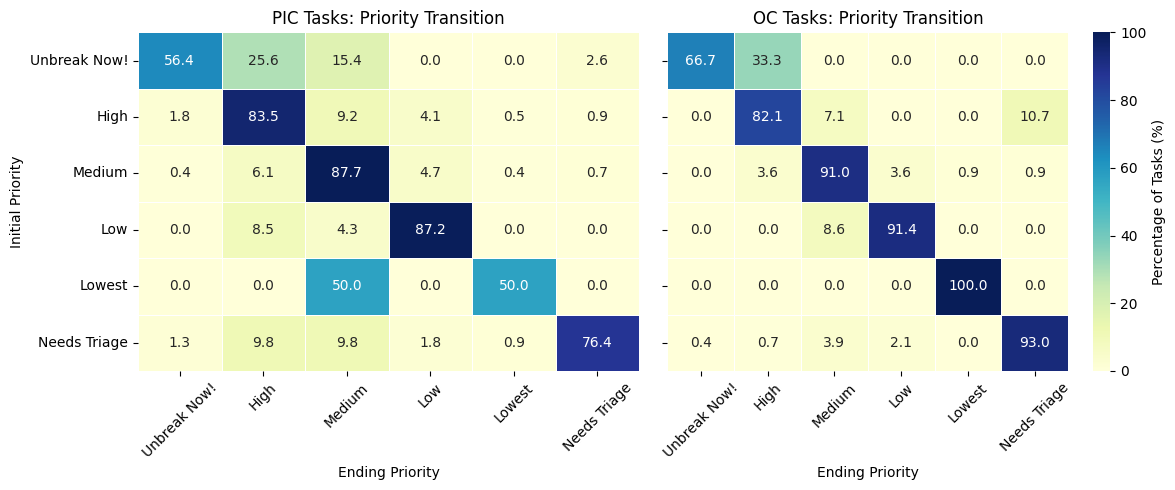

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define the desired order of priorities for consistent display
priority_order = ['Unbreak Now!', 'High', 'Medium', 'Low', 'Lowest', 'Needs Triage']

# --- PIC Tasks ---
# Filter for PIC tasks
pic_tasks_priorities = pic_tasks[['initialPriority', 'priority']].copy()

# Ensure priority columns are categorical with the correct order
pic_tasks_priorities['initialPriority'] = pd.Categorical(pic_tasks_priorities['initialPriority'], categories=priority_order, ordered=True)
pic_tasks_priorities['priority'] = pd.Categorical(pic_tasks_priorities['priority'], categories=priority_order, ordered=True)

# Create a contingency table (cross-tabulation) of initial vs. ending priorities
pic_priority_transition_matrix = pd.crosstab(pic_tasks_priorities['initialPriority'], pic_tasks_priorities['priority'], normalize='index') * 100

# Reindex to ensure consistent order
pic_priority_transition_matrix = pic_priority_transition_matrix.reindex(index=priority_order, columns=priority_order, fill_value=0)


# --- OC Tasks ---
# Filter for OC tasks
oc_tasks_priorities = oc_tasks[['initialPriority', 'priority']].copy()

# Ensure priority columns are categorical with the correct order
oc_tasks_priorities['initialPriority'] = pd.Categorical(oc_tasks_priorities['initialPriority'], categories=priority_order, ordered=True)
oc_tasks_priorities['priority'] = pd.Categorical(oc_tasks_priorities['priority'], categories=priority_order, ordered=True)

# Create a contingency table (cross-tabulation) of initial vs. ending priorities
oc_priority_transition_matrix = pd.crosstab(oc_tasks_priorities['initialPriority'], oc_tasks_priorities['priority'], normalize='index') * 100

# Reindex to ensure consistent order
oc_priority_transition_matrix = oc_priority_transition_matrix.reindex(index=priority_order, columns=priority_order, fill_value=0)


# --- Plotting ---
size = (5, 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True) # Adjusted figsize for two plots

# PIC Heatmap
sns.heatmap(pic_priority_transition_matrix, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5, cbar=False, ax=axes[0])
axes[0].set_title('PIC Tasks: Priority Transition')
axes[0].set_xlabel('Ending Priority')
axes[0].set_ylabel('Initial Priority')
axes[0].tick_params(axis='x', labelrotation=45) # Corrected parameter
axes[0].tick_params(axis='y', rotation=0)

# OC Heatmap
sns.heatmap(oc_priority_transition_matrix, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5, cbar_kws={'label': 'Percentage of Tasks (%)'}, ax=axes[1])
axes[1].set_title('OC Tasks: Priority Transition')
axes[1].set_xlabel('Ending Priority')
axes[1].set_ylabel('') # Y-label shared
axes[1].tick_params(axis='x', labelrotation=45) # Corrected parameter
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()


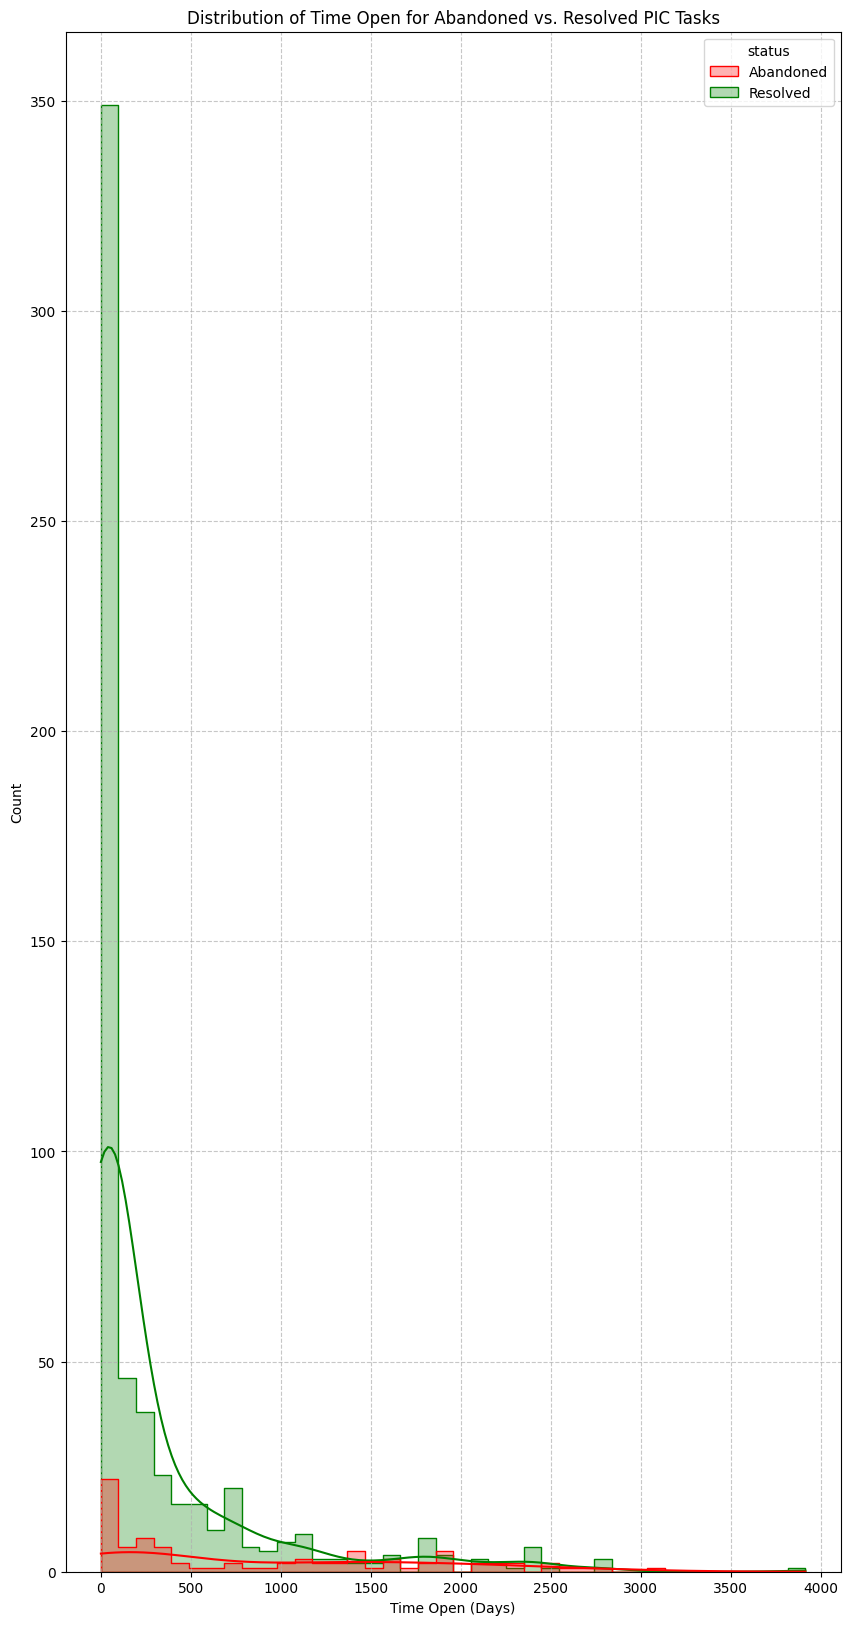

Histograms for abandoned vs. resolved PIC tasks generated.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure pic_tasks DataFrame is available from previous cells
if 'pic_tasks' not in locals():
    print("Error: pic_tasks DataFrame not found. Please ensure the data loading and cleaning cells have been executed.")
else:
    # Define abandoned tasks within PIC tasks
    abandoned_pic_tasks = pic_tasks[
        (pic_tasks['isDeclined'] == True) |
        (pic_tasks['isDuplicate'] == True) |
        (pic_tasks['isInvalid'] == True)
    ].copy()

    # Define resolved tasks within PIC tasks
    resolved_pic_tasks = pic_tasks[pic_tasks['isResolved'] == True].copy()

    # Add a 'status' column to differentiate for plotting
    abandoned_pic_tasks['status'] = 'Abandoned'
    resolved_pic_tasks['status'] = 'Resolved'

    # Combine the two groups for plotting
    plot_df = pd.concat([abandoned_pic_tasks, resolved_pic_tasks])

    plt.figure(figsize=(10, 20))
    sns.histplot(
        data=plot_df,
        x='time_open_days',
        hue='status',
        common_norm=False,
        kde=True,
        palette={'Abandoned': 'red', 'Resolved': 'green'},
        element='step',
        fill=True,
        alpha=0.3
    )
    plt.title('Distribution of Time Open for Abandoned vs. Resolved PIC Tasks')
    plt.xlabel('Time Open (Days)')
    plt.ylabel('Count')
    plt.grid(True, linestyle='--', alpha=0.7)
    #plt.yscale('log') # Added this line for log scale on y-axis
    plt.show()

    print("Histograms for abandoned vs. resolved PIC tasks generated.")